#### Import Packages

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

In [2]:
#import dataset
df=pd.read_csv("E:\\Bus Delay Prediction ML Project\\data\\ttc-bus-delay-data-2023.csv")
df.head()

,Date,Route,Time,Day,Location,Incident,Min Delay,Min Gap,Direction,Vehicle
0,1-Jan-23,91,02:30,Sunday,WOODBINE AND MORTIMER,Diversion,81,111,NaN,8772
1,1-Jan-23,69,02:34,Sunday,WARDEN STATION,Security,22,44,S,8407
2,1-Jan-23,35,03:06,Sunday,JANE STATION,Cleaning - Unsanitary,30,60,N,1051
3,1-Jan-23,900,03:14,Sunday,KIPLING STATION,Security,17,17,NaN,3334
4,1-Jan-23,85,03:43,Sunday,MEADOWALE LOOP,Security,1,1,NaN,1559


In [3]:
#check how many rows and columns
df.shape

(50913, 10)

In [4]:
#check the values are duplicate and remove the duplicate values
df.duplicated().sum()
df=df.drop_duplicates()
df.duplicated().sum()
df.shape

(50726, 10)

In [5]:
#split date into date-month-year and time into hour and minute.
#route column takes only digit
df['Route']=pd.to_numeric(df['Route'].astype(str).str.extract(r'(\d+)', expand=False),errors='coerce')
df['Date']=pd.to_datetime(df['Date'],format='%d-%b-%y')
df['Time']=pd.to_datetime(df['Time'],format='%H:%M')
df["Day_Date"] = df["Date"].dt.day
df["Month"] = df["Date"].dt.month
df["Year"] = df["Date"].dt.year
df["Hour"] = df["Time"].dt.hour
df["Minute"] = df["Time"].dt.minute

In [6]:
#remove unwanted columns
df.drop(['Time','Date','Location'],axis=1,inplace=True)
df.head()


,Route,Day,Incident,Min Delay,Min Gap,Direction,Vehicle,Day_Date,Month,Year,Hour,Minute
0,91.0,Sunday,Diversion,81,111,NaN,8772,1,1,2023,2,30
1,69.0,Sunday,Security,22,44,S,8407,1,1,2023,2,34
2,35.0,Sunday,Cleaning - Unsanitary,30,60,N,1051,1,1,2023,3,6
3,900.0,Sunday,Security,17,17,NaN,3334,1,1,2023,3,14
4,85.0,Sunday,Security,1,1,NaN,1559,1,1,2023,3,43


In [7]:
#replace unwanted values
df.replace({'Incident':{'Road Blocked - NON-TTC Collision':'Road Blocked','Collision - TTC':'Collision','Held By':'Tire Puncher','Operations - Operator':'Operations','Cleaning - Unsanitary':'Cleaning'}},inplace=True)
df.replace({'Direction':{'B':'W','`':'E','1':'S','/':'N','L':'W','D':'W','G':'W','H':'E','7':'S',str('\\'):'E'}},inplace=True)
df['Incident'].value_counts()
df['Vehicle']=df['Vehicle'].astype('str')
df


,Route,Day,Incident,Min Delay,Min Gap,Direction,Vehicle,Day_Date,Month,Year,Hour,Minute
0,91.0,Sunday,Diversion,81,111,NaN,8772,1,1,2023,2,30
1,69.0,Sunday,Security,22,44,S,8407,1,1,2023,2,34
2,35.0,Sunday,Cleaning,30,60,N,1051,1,1,2023,3,6
3,900.0,Sunday,Security,17,17,NaN,3334,1,1,2023,3,14
4,85.0,Sunday,Security,1,1,NaN,1559,1,1,2023,3,43
...,...,...,...,...,...,...,...,...,...,...,...,...
50908,84.0,Thursday,Mechanical,10,20,E,3581,30,11,2023,0,1
50909,960.0,Thursday,Mechanical,24,48,E,8390,30,11,2023,0,25
50910,116.0,Thursday,Cleaning,10,20,W,1652,30,11,2023,0,44
50911,7.0,Thursday,Operations,11,21,N,8192,30,11,2023,0,48


In [8]:
df.replace({'Vehicle':{'0':None}},inplace=True)

df.head(20)

,Route,Day,Incident,Min Delay,Min Gap,Direction,Vehicle,Day_Date,Month,Year,Hour,Minute
0,91.0,Sunday,Diversion,81,111,NaN,8772,1,1,2023,2,30
1,69.0,Sunday,Security,22,44,S,8407,1,1,2023,2,34
2,35.0,Sunday,Cleaning,30,60,N,1051,1,1,2023,3,6
3,900.0,Sunday,Security,17,17,NaN,3334,1,1,2023,3,14
4,85.0,Sunday,Security,1,1,NaN,1559,1,1,2023,3,43
5,40.0,Sunday,Emergency Services,0,0,NaN,None,1,1,2023,3,47
6,336.0,Sunday,Diversion,138,168,NaN,9220,1,1,2023,3,52
7,52.0,Sunday,Emergency Services,30,60,E,3520,1,1,2023,4,25
8,24.0,Sunday,Cleaning,20,40,W,8404,1,1,2023,4,35
9,36.0,Sunday,Diversion,334,344,NaN,3524,1,1,2023,5,18


#### Check and cleaning the null values

In [9]:
#checking null values
df.isna().sum()

Route         628
Day             0
Incident        0
Min Delay       0
Min Gap         0
Direction    8758
Vehicle      2185
Day_Date        0
Month           0
Year            0
Hour            0
Minute          0
dtype: int64

In [10]:
#understanding about data
df.info()

<class 'pandas.DataFrame'>
Index: 50726 entries, 0 to 50912
Data columns (total 12 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Route      50098 non-null  float64
 1   Day        50726 non-null  str    
 2   Incident   50726 non-null  str    
 3   Min Delay  50726 non-null  int64  
 4   Min Gap    50726 non-null  int64  
 5   Direction  41968 non-null  str    
 6   Vehicle    48541 non-null  object 
 7   Day_Date   50726 non-null  int32  
 8   Month      50726 non-null  int32  
 9   Year       50726 non-null  int32  
 10  Hour       50726 non-null  int32  
 11  Minute     50726 non-null  int32  
dtypes: float64(1), int32(5), int64(2), object(1), str(3)
memory usage: 4.1+ MB


In [11]:
#cleaning null values and replace it
#route column changed string into integer
df.fillna({'Direction':df['Direction'].mode()[0]},inplace=True)
df.fillna({'Route':df['Route'].median()},inplace=True)
df.fillna({'Vehicle':df['Vehicle'].mode()[0]},inplace=True)
df['Route']=df['Route'].astype('int64')
df['Vehicle']=df['Vehicle'].astype('int64')
df.head(20)


,Route,Day,Incident,Min Delay,Min Gap,Direction,Vehicle,Day_Date,Month,Year,Hour,Minute
0,91,Sunday,Diversion,81,111,N,8772,1,1,2023,2,30
1,69,Sunday,Security,22,44,S,8407,1,1,2023,2,34
2,35,Sunday,Cleaning,30,60,N,1051,1,1,2023,3,6
3,900,Sunday,Security,17,17,N,3334,1,1,2023,3,14
4,85,Sunday,Security,1,1,N,1559,1,1,2023,3,43
5,40,Sunday,Emergency Services,0,0,N,8339,1,1,2023,3,47
6,336,Sunday,Diversion,138,168,N,9220,1,1,2023,3,52
7,52,Sunday,Emergency Services,30,60,E,3520,1,1,2023,4,25
8,24,Sunday,Cleaning,20,40,W,8404,1,1,2023,4,35
9,36,Sunday,Diversion,334,344,N,3524,1,1,2023,5,18


In [12]:
#describe the target column
df["Min Delay"].describe()

count    50726.000000
mean        20.487777
std         51.375624
min          0.000000
25%          9.000000
50%         11.000000
75%         20.000000
max        998.000000
Name: Min Delay, dtype: float64

In [13]:
#sort the values
print("\nLargest 20 delay values:")
df.sort_values(by="Min Delay",ascending=False).head(20)


Largest 20 delay values:


,Route,Day,Incident,Min Delay,Min Gap,Direction,Vehicle,Day_Date,Month,Year,Hour,Minute
31111,121,Wednesday,Diversion,998,101,E,8530,9,8,2023,9,5
20796,75,Monday,Diversion,997,101,N,8339,5,6,2023,7,24
7184,77,Thursday,Diversion,997,105,W,7962,23,2,2023,8,58
44280,68,Wednesday,Diversion,994,102,N,3288,25,10,2023,4,56
35694,91,Tuesday,Diversion,993,100,S,8766,5,9,2023,6,58
8467,37,Saturday,General Delay,981,981,N,8073,4,3,2023,7,17
1979,7,Wednesday,Diversion,972,982,N,8339,18,1,2023,10,49
15818,102,Friday,Diversion,962,992,N,8339,28,4,2023,7,6
3517,55,Sunday,Diversion,960,990,N,7951,29,1,2023,10,3
44966,7,Saturday,Diversion,960,969,N,9006,28,10,2023,12,22


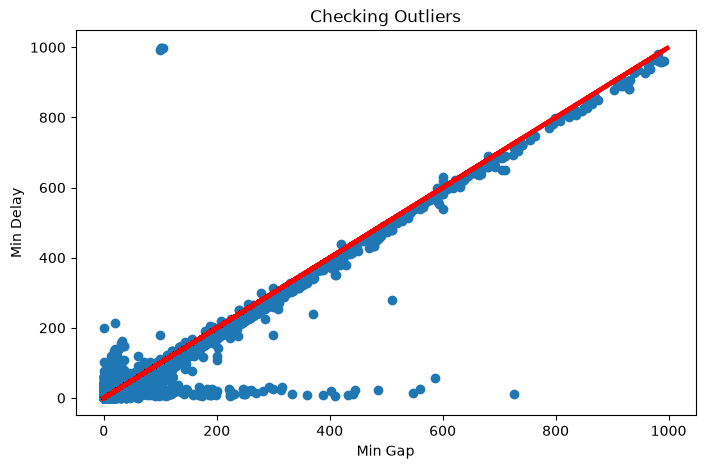

In [14]:
#checking outliers
plt.figure(figsize=(8, 5))
plt.scatter(df['Min Gap'],df['Min Delay'])
plt.plot([df['Min Gap'],df['Min Delay']],[df['Min Gap'],df['Min Delay']],linestyle='solid',linewidth=3,color='red')
plt.xlabel('Min Gap')
plt.ylabel('Min Delay')

plt.title('Checking Outliers')

plt.show()

In [15]:
#clear outliers
Q1 = df["Min Delay"].quantile(0.25)
Q3 = df["Min Delay"].quantile(0.75)

IQR = Q3 - Q1

upper = Q3 + 1.5 * IQR
lower = Q1 - 1.5 * IQR


df = df[(df["Min Delay"] > upper) | (df["Min Delay"] < lower)]
#df = df[(df['Min Delay'] < lower) |(df['Min Delay'] > upper)]

print("Number of outliers:", len(df))

print("Upper limit:", upper)
print("Lower limit:", lower)
#print("High delay records:", len(df))

df.head(20)

Number of outliers: 2700
Upper limit: 36.5
Lower limit: -7.5


,Route,Day,Incident,Min Delay,Min Gap,Direction,Vehicle,Day_Date,Month,Year,Hour,Minute
0,91,Sunday,Diversion,81,111,N,8772,1,1,2023,2,30
6,336,Sunday,Diversion,138,168,N,9220,1,1,2023,3,52
9,36,Sunday,Diversion,334,344,N,3524,1,1,2023,5,18
11,300,Sunday,Diversion,138,148,E,3339,1,1,2023,6,4
44,87,Sunday,Diversion,50,70,E,8500,1,1,2023,11,0
127,43,Monday,Road Blocked,132,142,N,3158,2,1,2023,13,9
149,79,Monday,Diversion,120,140,S,1128,2,1,2023,18,43
150,83,Monday,Diversion,361,377,N,8339,2,1,2023,18,50
157,56,Monday,Diversion,382,408,N,8339,2,1,2023,20,46
160,47,Monday,Diversion,52,62,S,8339,2,1,2023,20,57


In [16]:
#clear null values
df.isna().sum()

Route        0
Day          0
Incident     0
Min Delay    0
Min Gap      0
Direction    0
Vehicle      0
Day_Date     0
Month        0
Year         0
Hour         0
Minute       0
dtype: int64

In [17]:
#encode categorical into numeric
from sklearn.preprocessing import LabelEncoder
inci=LabelEncoder()
direc=LabelEncoder()
day=LabelEncoder()
df['Incident']=inci.fit_transform(df['Incident'])
df['Direction']=inci.fit_transform(df['Direction'])
df['Day']=day.fit_transform(df['Day'])
df.head()


,Route,Day,Incident,Min Delay,Min Gap,Direction,Vehicle,Day_Date,Month,Year,Hour,Minute
0,91,3,2,81,111,1,8772,1,1,2023,2,30
6,336,3,2,138,168,1,9220,1,1,2023,3,52
9,36,3,2,334,344,1,3524,1,1,2023,5,18
11,300,3,2,138,148,0,3339,1,1,2023,6,4
44,87,3,2,50,70,0,8500,1,1,2023,11,0


In [18]:
#split input features and target(Min delay column)
x=df.drop(['Min Delay'],axis=1)
y=df['Min Delay']

#### Split the x and y as train and test data

In [19]:
from sklearn.model_selection import train_test_split
train_x,test_x,train_y,test_y=train_test_split(x,y,test_size=0.2,random_state=42)
train_x.head()

,Route,Day,Incident,Min Gap,Direction,Vehicle,Day_Date,Month,Year,Hour,Minute
41888,52,6,2,354,0,3577,11,10,2023,12,57
25186,116,4,2,135,1,8339,6,7,2023,6,14
41043,61,0,2,148,1,8339,6,10,2023,10,23
34450,985,1,2,80,0,3426,28,8,2023,23,46
48073,334,6,2,240,0,8785,15,11,2023,2,1


In [20]:
#copy the original data
train_x_copy=train_x.copy()
train_y_copy=train_y.copy()

#### Scaling the input features to avoid data leakage

In [21]:
from sklearn.preprocessing import StandardScaler
sc=StandardScaler()
train_x=sc.fit_transform(train_x)
test_x=sc.transform(test_x)

 Three models are used for this project LinearRegression,DecisionTreeRegressor and RandomForestRegressor 

In [22]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

comparing the baseline models and balance models with metrics such as mean absolute error,mean squared error and r2 score.Check mean absolute error and mean squared error as which model is lowest,also check r2 score which model get highest.

In [23]:
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

In [24]:
from sklearn.model_selection import KFold, cross_val_score
kf = KFold(n_splits=5, shuffle=True, random_state=42)

Include training data into the models

In [25]:
#baseline model
lr=LinearRegression().fit(train_x,train_y)
print("Linear Regression train_test_split score:",lr.score(train_x,train_y))
pred_y1=lr.predict(test_x)
line=pd.DataFrame({"Linear Regression": [mean_absolute_error(test_y,pred_y1), mean_squared_error(test_y,pred_y1), r2_score(test_y,pred_y1)]}, index=['MAE', 'MSE', 'R2'])
line

Linear Regression train_test_split score: 0.9382696557733653


,Linear Regression
MAE,14.902038
MSE,3361.677939
R2,0.901890


In [26]:
dtr=DecisionTreeRegressor(random_state=42).fit(train_x,train_y)
rfr=RandomForestRegressor(random_state=42,n_jobs=-1).fit(train_x,train_y)

In [27]:

score=pd.DataFrame({"Trained score of models":[lr.score(train_x,train_y), dtr.score(train_x,train_y), rfr.score(train_x,train_y)]}, index=['Linear Regression', 'Decision Tree', 'Random Forest'])
score

,Trained score of models
Linear Regression,0.938270
Decision Tree,1.000000
Random Forest,0.988409


Predict the balance 2 models

In [28]:
pred_y2=dtr.predict(test_x)
pred_y3=rfr.predict(test_x)


Used three metrics mean absolute error,mean square error and r2 score

In [29]:
pred_df=pd.DataFrame({"Linear Regression":[mean_absolute_error(test_y,pred_y1),mean_squared_error(test_y,pred_y1),r2_score(test_y,pred_y1)],'Decision Tree Regressor':[mean_absolute_error(test_y,pred_y2),mean_squared_error(test_y,pred_y2),r2_score(test_y,pred_y2)],'RandomForestRegressor':[mean_absolute_error(test_y,pred_y3),mean_squared_error(test_y,pred_y3),r2_score(test_y,pred_y3)]},index=['MAE','MSE','R2 Score'])
pred_df

,Linear Regression,Decision Tree Regressor,RandomForestRegressor
MAE,14.902038,13.574074,12.544019
MSE,3361.677939,3331.251852,3328.095324
R2 Score,0.901890,0.902778,0.902870


After comparison of this four models,RandomForestRegressor is the best model.This model got MAE as 12.628093,MSE as 3232.265399 and R2 Score 0.905667

Got a straight line between input and target

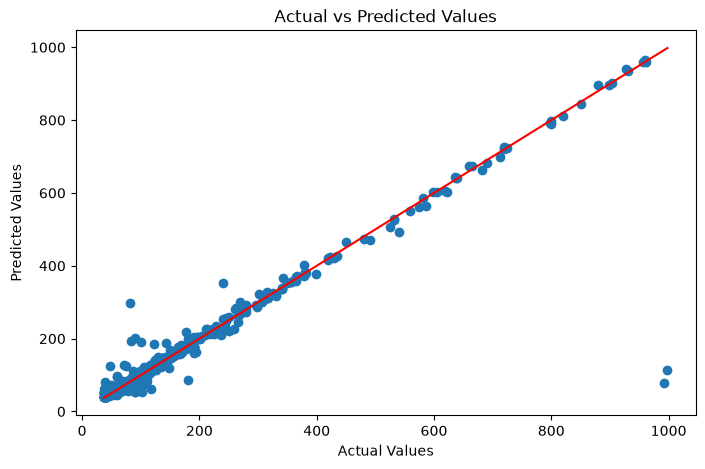

In [30]:
plt.figure(figsize=(8, 5))
plt.scatter(test_y, pred_y3)
plt.plot([test_y.min(), test_y.max()],[test_y.min(), test_y.max()],color='red')
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')

plt.title('Actual vs Predicted Values')

plt.show()

Actual-The real bus delay from your dataset

Predicted-The delay predicted by the ML model

Error-Difference between actual and predicted delay

Absolute_Error-Error without the negative sign

In [31]:
compare=pd.DataFrame({'Actual':test_y,'Predicted':pred_y3})
compare['Error'] = (
    compare['Actual'] - compare['Predicted']
)

compare['Absolute_Error'] = (
    compare['Error'].abs()
)

compare.head(30)

,Actual,Predicted,Error,Absolute_Error
23453,60,63.57,-3.57,3.57
21630,123,186.39,-63.39,63.39
19601,48,50.79,-2.79,2.79
13950,43,50.51,-7.51,7.51
21695,90,82.03,7.97,7.97
8702,314,314.27,-0.27,0.27
14584,171,169.49,1.51,1.51
17706,180,199.35,-19.35,19.35
41656,100,189.46,-89.46,89.46
11499,80,74.16,5.84,5.84


Absolute_Error is large, the model made a large prediction mistake.

In [32]:
largest_errors = compare.sort_values(
    by='Absolute_Error',
    ascending=False
)

largest_errors.head(10)

,Actual,Predicted,Error,Absolute_Error
35694,993,78.09,914.91,914.91
31111,998,113.94,884.06,884.06
46852,81,297.12,-216.12,216.12
39307,240,351.83,-111.83,111.83
43547,90,200.91,-110.91,110.91
20632,84,193.51,-109.51,109.51
3569,180,85.38,94.62,94.62
41656,100,189.46,-89.46,89.46
38790,47,126.08,-79.08,79.08
21630,123,186.39,-63.39,63.39


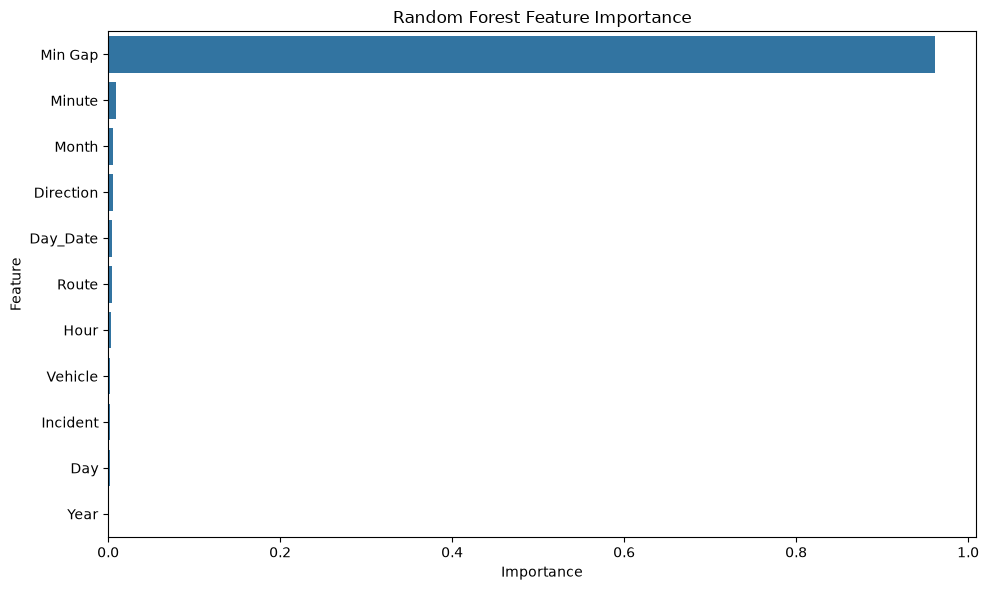

Min Gap      0.961145
Minute       0.009014
Month        0.005648
Direction    0.005213
Day_Date     0.004761
Route        0.004168
Hour         0.003497
Vehicle      0.002434
Incident     0.002095
Day          0.002026
Year         0.000000
dtype: float64

In [33]:
feature_importance = pd.Series(
    rfr.feature_importances_,
    index=x.columns
).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x=feature_importance.values, y=feature_importance.index)
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")
plt.tight_layout()
plt.show()

feature_importance

In [34]:
results = cross_val_score(lr, x, y, scoring='r2', cv=kf)
print("Cross-validation scores LinearRegression:", results)
results = cross_val_score(dtr, x, y, scoring='r2', cv=kf)
print("Cross-validation scores DecisionTreeRegressor:", results)
results = cross_val_score(rfr, x, y, scoring='r2', cv=kf)
print("Cross-validation scores RandomForestRegressor:", results)

Cross-validation scores LinearRegression: [0.90188994 0.96815496 0.87236763 0.93826457 0.97464814]
Cross-validation scores DecisionTreeRegressor: [0.90278279 0.85440488 0.82381415 0.89259959 0.92058622]
Cross-validation scores RandomForestRegressor: [0.90523    0.9666535  0.87285597 0.93947652 0.97607961]


In [35]:
from sklearn.model_selection import GridSearchCV,RandomizedSearchCV
param_grid = {
    'fit_intercept': [True, False],
    'positive': [True, False],
    'copy_X': [True, False]
}
grid = GridSearchCV(lr,param_grid,cv=kf,scoring='r2')
    #n_iter=10
    #param_distribution for randomizedsearchcv

grid.fit(train_x, train_y)

print("Best Parameters:", grid.best_params_)
print("Best Score:", grid.best_score_)

best_model = grid.best_estimator_

Best Parameters: {'copy_X': True, 'fit_intercept': True, 'positive': False}
Best Score: 0.9385310787155511


In [36]:
dt_param_dist = {
    'max_depth': [None, 5, 10, 20, 30],
    'min_samples_split': [2, 5, 10, 20],
    'min_samples_leaf': [1, 2, 4, 8],
    'max_features': [None, 'sqrt', 'log2']
}

dt_search = GridSearchCV(
    dtr,
    dt_param_dist,
    #n_iter=20,
    scoring='r2',
    cv=kf
)

dt_search.fit(train_x, train_y)

print("Decision tree best parameters:", dt_search.best_params_)
print("Decision tree best CV R²:", dt_search.best_score_)
best_dt_model = dt_search.best_estimator_




Decision tree best parameters: {'max_depth': 10, 'max_features': None, 'min_samples_leaf': 8, 'min_samples_split': 20}
Decision tree best CV R²: 0.940901141101761


In [37]:
rf_param_dist = {
    'n_estimators': [100, 200, 300, 500],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': [1.0, 'sqrt', 'log2']
}

rf_search = RandomizedSearchCV(
    rfr,
    rf_param_dist,
    n_iter=10,
    scoring='r2',
    cv=kf,n_jobs=-1
)

rf_search.fit(train_x, train_y)

print("Random forest best parameters:", rf_search.best_params_)
print("Random forest best CV R²:", rf_search.best_score_)
best_rf_model = rf_search.best_estimator_

Random forest best parameters: {'n_estimators': 300, 'min_samples_split': 10, 'min_samples_leaf': 4, 'max_features': 1.0, 'max_depth': 30}
Random forest best CV R²: 0.9443046260096182


In [38]:
score=pd.DataFrame({"Trained score of tuned models":[best_model.score(train_x,train_y), best_dt_model.score(train_x,train_y), best_rf_model.score(train_x,train_y)]}, index=['Linear Regression', 'Decision Tree', 'Random Forest'])
score

,Trained score of tuned models
Linear Regression,0.938270
Decision Tree,0.959297
Random Forest,0.963153


In [39]:
pred_y1=best_model.predict(test_x)
pred_y2=best_dt_model.predict(test_x)
pred_y3=best_rf_model.predict(test_x)

After tuning got score

In [40]:
pred_df=pd.DataFrame({"LinearRegression":[mean_absolute_error(test_y,pred_y1),mean_squared_error(test_y,pred_y1),r2_score(test_y,pred_y1)],'Decision Tree Regressor':[mean_absolute_error(test_y,pred_y2),mean_squared_error(test_y,pred_y2),r2_score(test_y,pred_y2)],'RandomForestRegressor':[mean_absolute_error(test_y,pred_y3),mean_squared_error(test_y,pred_y3),r2_score(test_y,pred_y3)]},index=['MAE','MSE','R2 Score'])
pred_df

,LinearRegression,Decision Tree Regressor,RandomForestRegressor
MAE,14.902038,14.087541,12.293241
MSE,3361.677939,3347.144716,3088.567719
R2 Score,0.901890,0.902314,0.909861


In the above table explains,RandomForestRegression got 0.9098 as a r2_score and MAE got 12.273.So,this the best model.

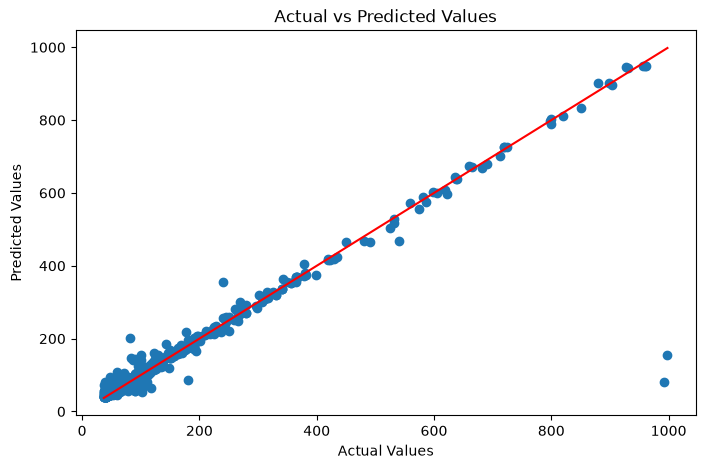

In [41]:
plt.figure(figsize=(8, 5))
plt.scatter(test_y, pred_y3)
plt.plot([test_y.min(), test_y.max()],[test_y.min(), test_y.max()],color='red')
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')

plt.title('Actual vs Predicted Values')

plt.show()

In [42]:
compare=pd.DataFrame({'Actual':test_y,'Predicted':pred_y3})
compare['Error'] = (
    compare['Actual'] - compare['Predicted']
)

compare['Absolute_Error'] = (
    compare['Error'].abs()
)

compare.head(30)

,Actual,Predicted,Error,Absolute_Error
23453,60,64.318890,-4.318890,4.318890
21630,123,159.419081,-36.419081,36.419081
19601,48,53.434909,-5.434909,5.434909
13950,43,52.724755,-9.724755,9.724755
21695,90,82.266417,7.733583,7.733583
8702,314,314.459412,-0.459412,0.459412
14584,171,169.578509,1.421491,1.421491
17706,180,196.733119,-16.733119,16.733119
41656,100,156.411264,-56.411264,56.411264
11499,80,73.802230,6.197770,6.197770


In [43]:
largest_errors = compare.sort_values(
    by='Absolute_Error',
    ascending=False
)

largest_errors.head(10)

,Actual,Predicted,Error,Absolute_Error
35694,993,80.095186,912.904814,912.904814
31111,998,155.272719,842.727281,842.727281
46852,81,200.989563,-119.989563,119.989563
39307,240,355.387835,-115.387835,115.387835
3569,180,85.317681,94.682319,94.682319
38958,540,467.401220,72.598780,72.598780
20632,84,147.197117,-63.197117,63.197117
41656,100,156.411264,-56.411264,56.411264
43547,90,144.598925,-54.598925,54.598925
5179,86,140.294606,-54.294606,54.294606


In [44]:
joblib.dump(inci, 'E:\\Bus Delay Prediction ML Project\\pkl files\\label_incident.pkl')#labelencoder
joblib.dump(direc, 'E:\\Bus Delay Prediction ML Project\\pkl files\\label_direction.pkl')#labelencoder day
joblib.dump(day, 'E:\\Bus Delay Prediction ML Project\\pkl files\\label_day.pkl')#labelencoder day

['E:\\Bus Delay Prediction ML Project\\pkl files\\label_day.pkl']

In [45]:
joblib.dump(sc,'E:\\Bus Delay Prediction ML Project\\pkl files\\scaled.pkl')#standard scaler

['E:\\Bus Delay Prediction ML Project\\pkl files\\scaled.pkl']

In [46]:
joblib.dump(best_rf_model,'E:\\Bus Delay Prediction ML Project\\pkl files\\randomforestregressor.pkl')#randomforestregressor model
joblib.dump(best_model,'E:\\Bus Delay Prediction ML Project\\pkl files\\linearregressor.pkl')#linearregressor model
joblib.dump(best_dt_model,'E:\\Bus Delay Prediction ML Project\\pkl files\\decisiontreeregressor.pkl')#decisiontreeregressor model

['E:\\Bus Delay Prediction ML Project\\pkl files\\decisiontreeregressor.pkl']